In [152]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# Obtaining Prices for Analysis

In [153]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  6 of 6 completed


In [154]:
# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

In [155]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()
# Save for Model Validation
data.to_csv('stock_quotes_and_rates.csv')       # Saving

In [156]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470741,11.523581,27.337229,1.442398,60.505947,47.728802,0.700
2010-01-05,6.481929,11.486513,27.387939,1.436596,60.221519,47.642601,0.699
2010-01-06,6.378826,11.589478,27.680922,1.440403,60.805820,47.599602,0.694
2010-01-07,6.367030,11.704796,27.173841,1.431803,61.497738,47.562500,0.692
2010-01-08,6.409363,11.820112,26.261097,1.441109,62.328075,47.728401,0.691
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,3.931
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,3.931
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,3.925


### Calculating Credit Risk

In [157]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    T = len(credit)
    t = np.arange(T)#.reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [158]:
credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

The `data` object now represents the risk factors $(Z_j)_{j\in I}$ of our portfolio, so that we can define $\ell_{[t]}^\Delta(Z)$.

In [159]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470741,11.523581,27.337229,1.442398,60.505947,47.728802,0.000019
2010-01-05,6.481929,11.486513,27.387939,1.436596,60.221519,47.642601,0.000019
2010-01-06,6.378826,11.589478,27.680922,1.440403,60.805820,47.599602,0.000019
2010-01-07,6.367030,11.704796,27.173841,1.431803,61.497738,47.562500,0.000019
2010-01-08,6.409363,11.820112,26.261097,1.441109,62.328075,47.728401,0.000019
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,0.000106
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,0.000106
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,0.000105


In [160]:
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

<Axes: xlabel='Date'>

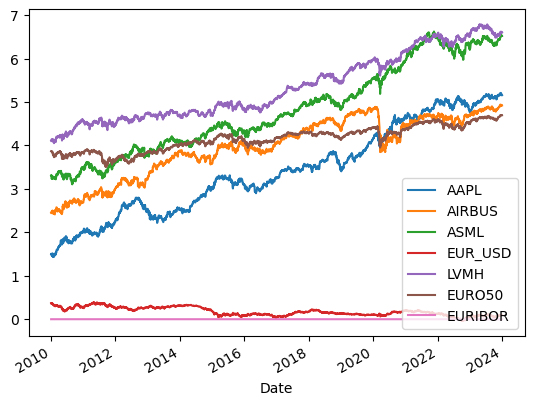

In [161]:
log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])

log_data.plot()

# Declaring Loss Operator

In [162]:
def loss_operator(Z, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = np.zeros(len(Z) - 1)
    loss_ind = Z[:-1].copy()
    T = len(Z) - 1
    t = np.arange(T)
    for Z_k, weight, name in zip(Z.values.T, weights, Z.columns):
        X_k = np.diff(Z_k)
        X_k = np.array([0] + X_k.tolist())
        X_k_shifted = X_k[1:] # from t = 2 to T
        X_k = X_k[:-1]  # from t = 1 to T - 1
        Z_k = Z_k[:-1]
        if name == 'AAPL':
            # Include EUR/USD exposure
            loss_sub = Value * weight * np.exp((Z_k - Z_k[0]) + (Z['EUR_USD'][:-1] - Z['EUR_USD'][0])) * X_k_shifted
        elif name == 'EURIBOR':
            # The time risk
            w = Value * np.exp(Z_k[0])
            loss_sub = -w * np.exp(-(T-t) * Z_k) * Z_k

            # Add credit risk
            loss_sub += Value * weight * np.exp(Z_k[0] - (T - t) * Z_k) * (T - t) * X_k
        else:
            loss_sub = Value * weight * np.exp(Z_k - Z_k[0]) * X_k_shifted
        loss += loss_sub
        loss_ind[name] = loss_sub * (1 / (weight)) if name != 'EUR_USD' else 0
    return -loss, -loss_ind

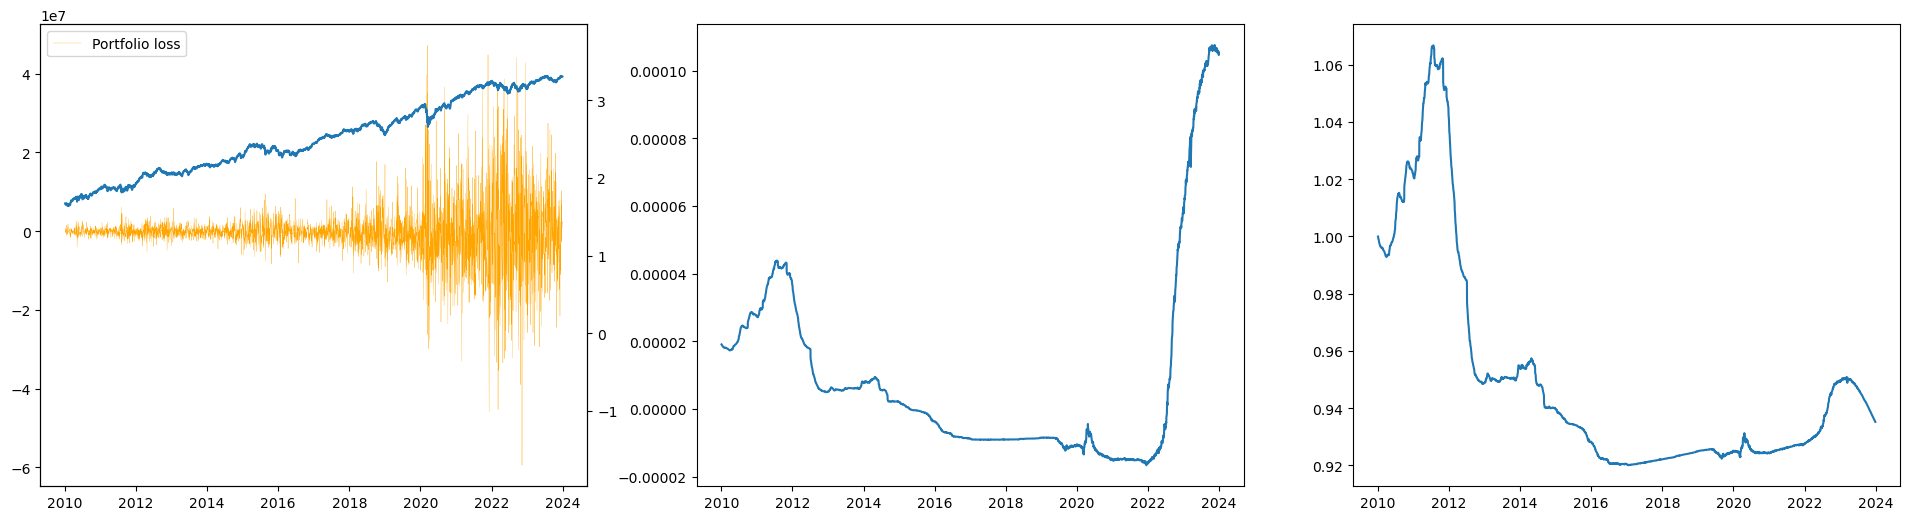

In [163]:
portfolio_loss, ind_loss = loss_operator(data, weights)
fig, axs = plt.subplots(1,3, figsize = (24, 6))
axs[0].plot(portfolio_loss, label = 'Portfolio loss', lw = 0.2, color='orange')
ax = axs[0].twinx()
PV = np.sum(weights * data, axis = 1)
ax.plot(PV)
ax.set_ylim(1.2 * max(-PV), 1.2 * max(PV))
axs[1].plot(data['EURIBOR'])
axs[2].plot(credit_val.loc[data.index])
axs[0].legend()
plt.show()

# Declaring methods to calculate VaR

### VaR CoVar

In [164]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.ppf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError()

In [165]:
window_size = 250 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

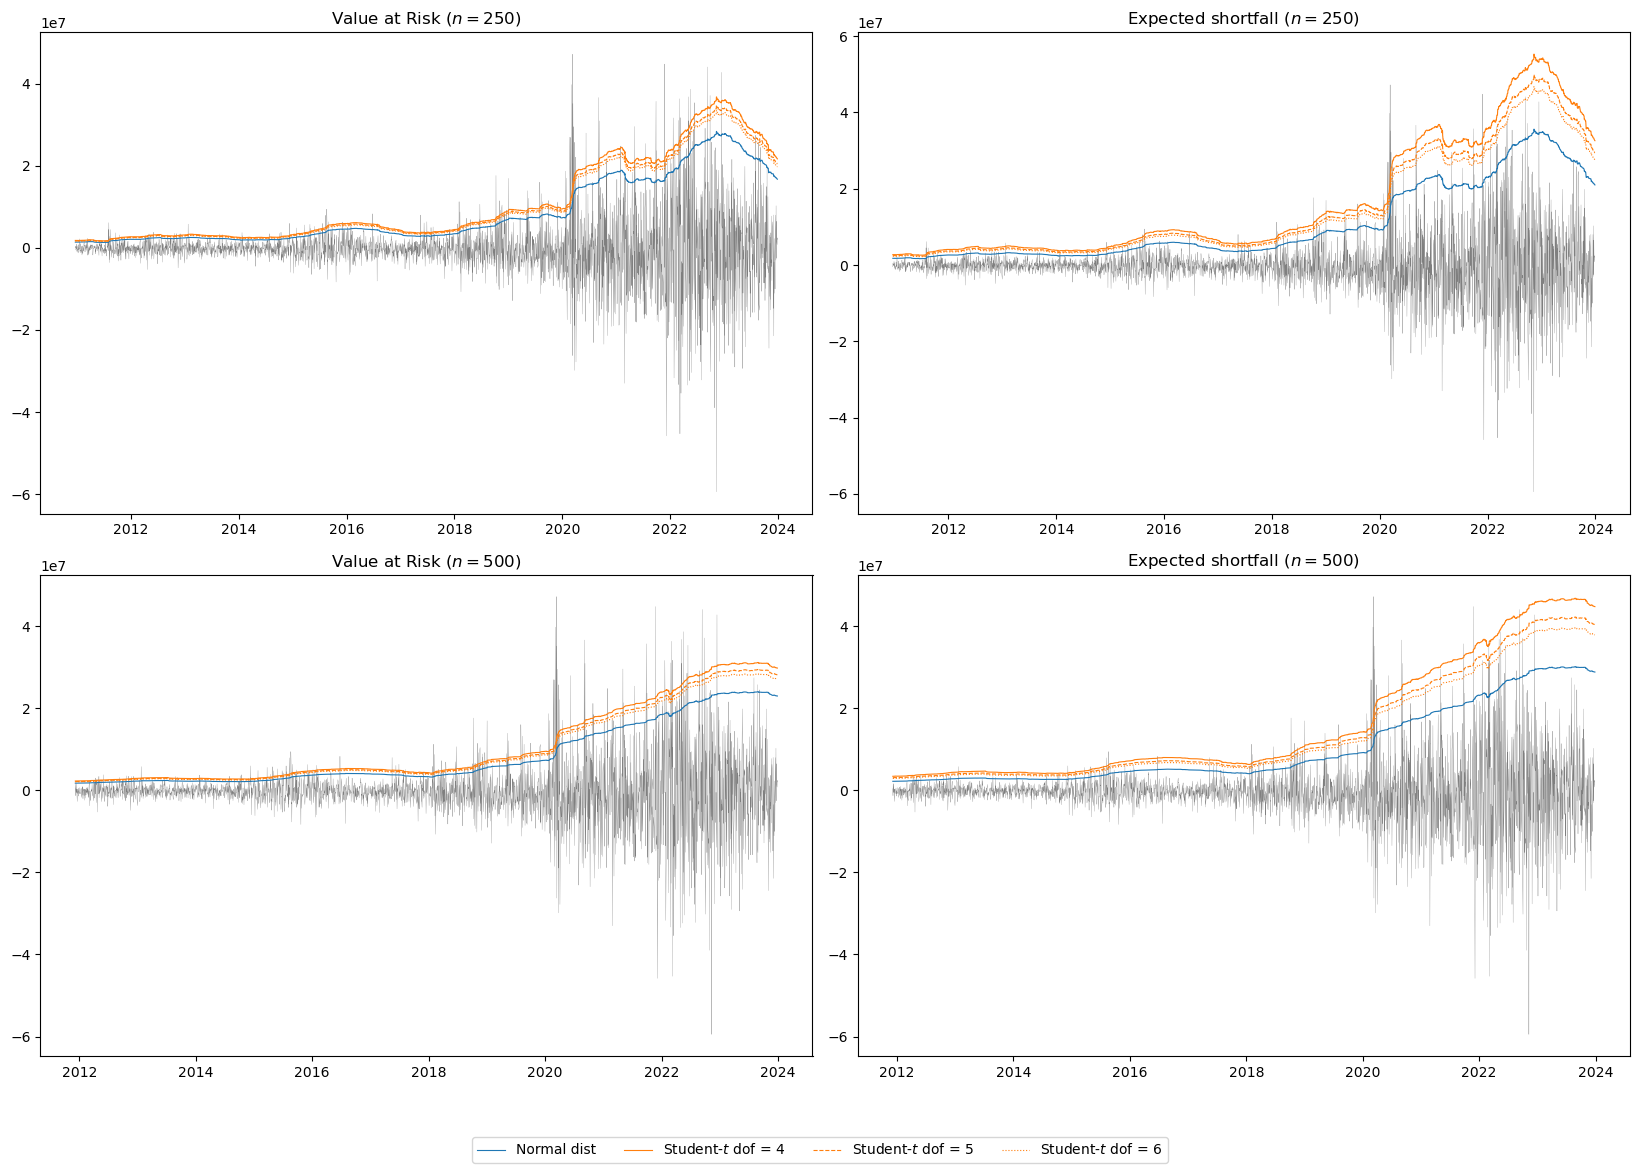

In [166]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

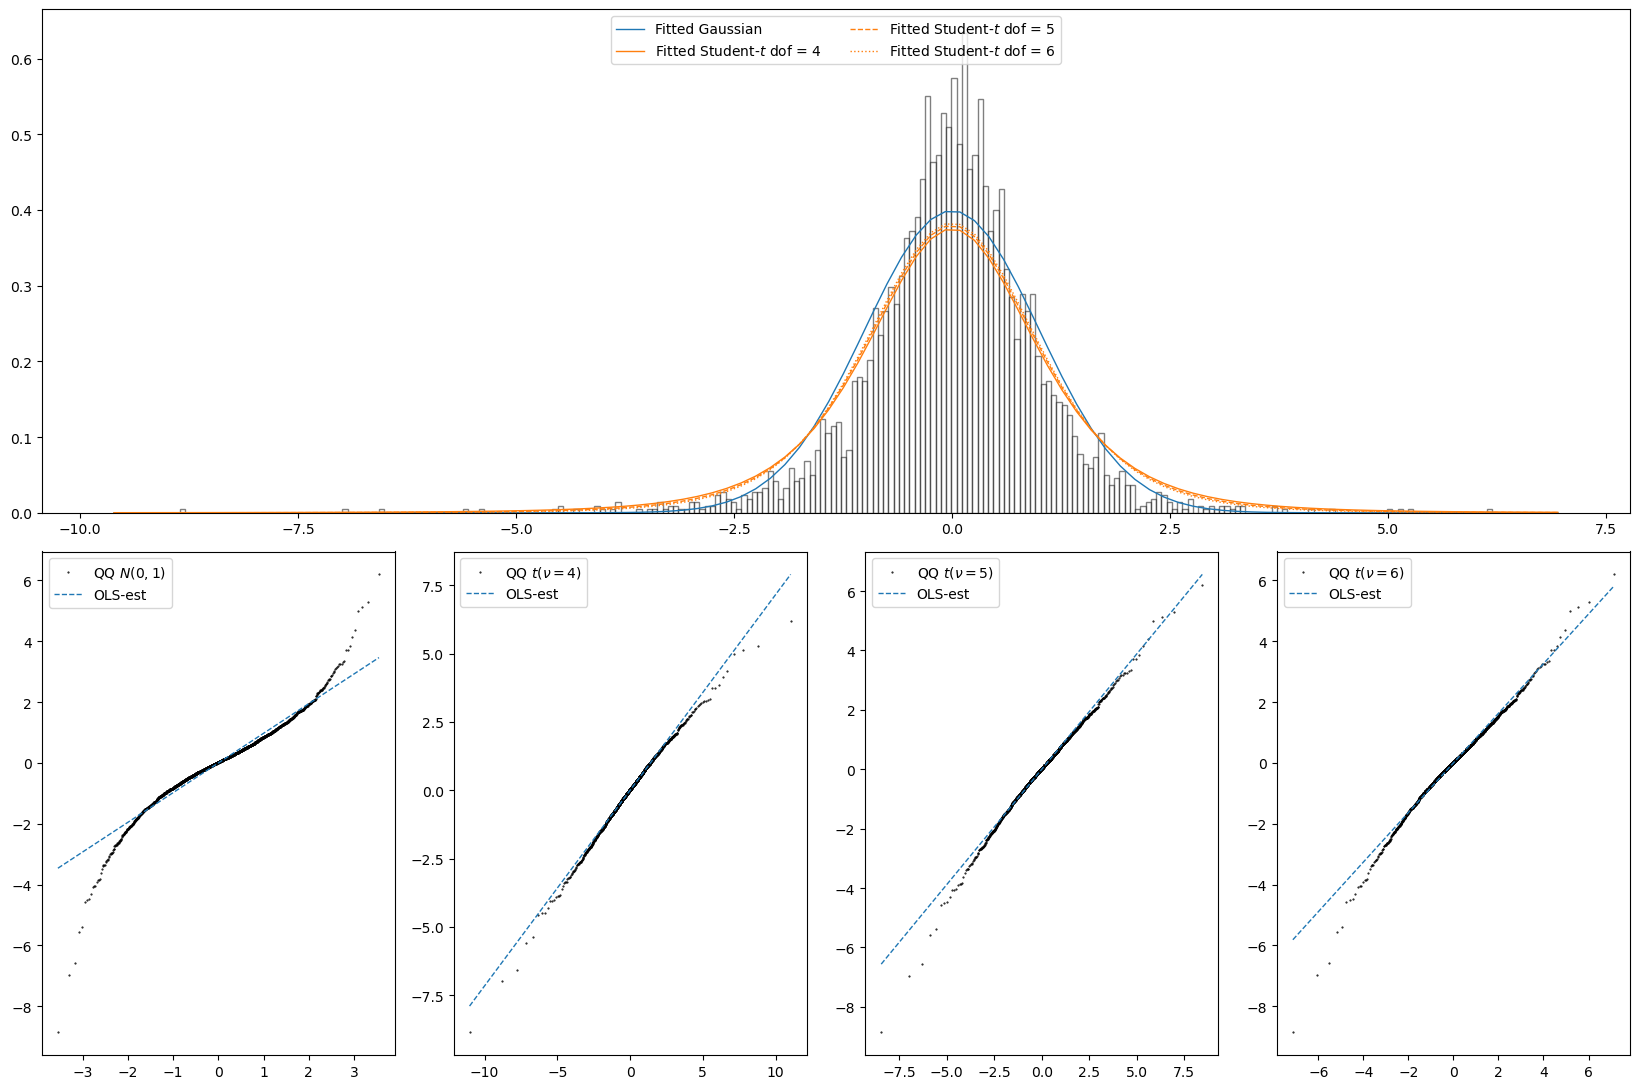

In [167]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (log_data.diff() @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [168]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [169]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df[window_size:]#.dropna()

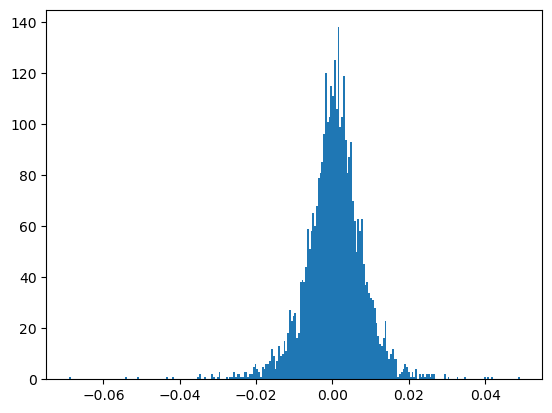

In [170]:
plt.hist(log_data.diff() @ weights, bins = 250)
plt.show()

In [171]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [172]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)

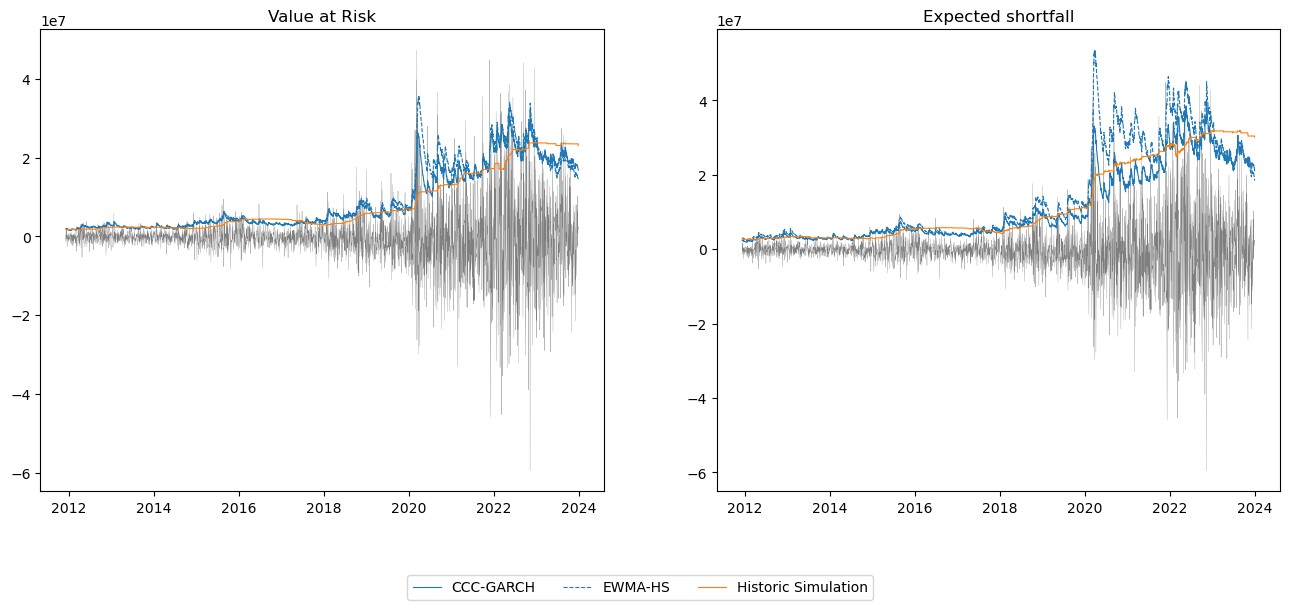

In [173]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss[window_size:].index, ES_GARCH[window_size:], label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss[window_size:].index, VaR_GARCH[window_size:], label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# BackTesting

## Obtaining Data

In [174]:
# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, VaR_alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    print("\nVaR Violations: ", sum(Violations_VaR))

    n = len(Violations_VaR)     # Number of trials
    p = 1-VaR_alpha              # Expected probability of violation per trial
    x = sum(Violations_VaR)     # Observed number of violations
    alpha = 0.05                # Significance level for the test

    # Calculate P-values for two-tail test
    p_value_left = stats.binom.cdf(x, n, p)  # Probability of x or fewer successes
    p_value_right = 1 - stats.binom.cdf(x - 1, n, p)  # Probability of x or more successes
    p_value = min(p_value_left, p_value_right) * 2  # Two-tailed P-value

    if p_value <= alpha:
        print("VaR Violations amount differs significantly from Expected")

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("\nAverage ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

In [175]:
data = log_data
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR

start_date = '2010-01-01'
end_date = '2024-01-01'
data = data[(data.index >= pd.to_datetime(start_date)) & (data.index < pd.to_datetime(end_date))]        # Keeping only the related dates
portfolio_loss, ind_loss = loss_operator(data, weights)

In [176]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = indexes_year_changes[0]                           # Days in the first period which are used to train VaR
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped

Indexes where year changes:  [259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


## VaR_95

In [177]:
alpha = .95

### Var-CoVar


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  17

Average ES Real and Theoretical:  2769450.1100471616 1987770.1417202037
ES t-Test significance of difference:  0.00894556146897365  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  16

Average ES Real and Theoretical:  2941958.570061111 2845149.4803335005
ES t-Test significance of difference:  0.44151805216487783  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3327107.6287444285 2924575.7550577144
ES t-Test significance of difference:  0.398708793409846  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=20

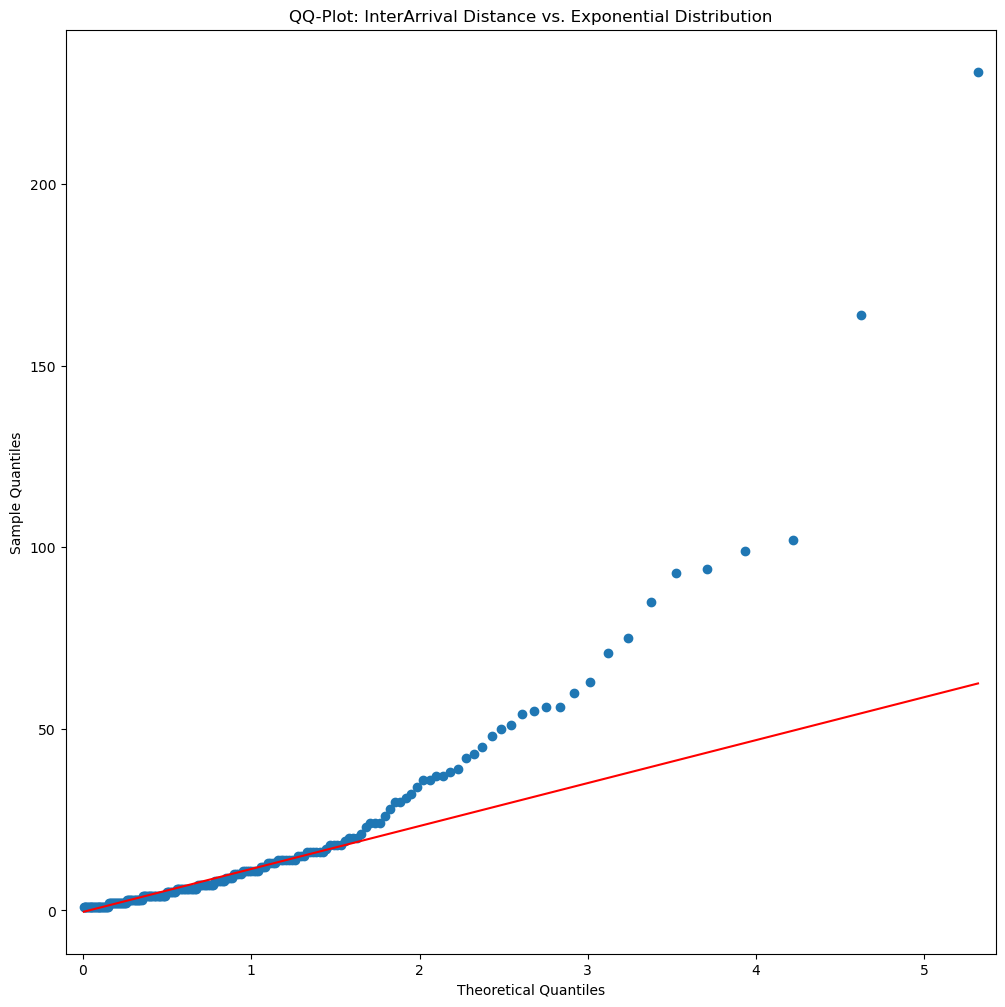


Average ES Real and Theoretical:  11563951.132444853 9533887.423547693
ES t-Test significance of difference:  0.008932411969358723  | Reject if <0.05




In [178]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  3181206.82956074 3087388.796093581
ES t-Test significance of difference:  0.7930863363042711  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  8

Average ES Real and Theoretical:  3396416.638371612 4463742.302222812
ES t-Test significance of difference:  6.778151493131261e-41  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  3
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4138677.397039436 4525817.008463777
ES t-Test significance of difference:  0.5688561396673668  | Reject if <0.05



Variance Covariance t-Stud

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


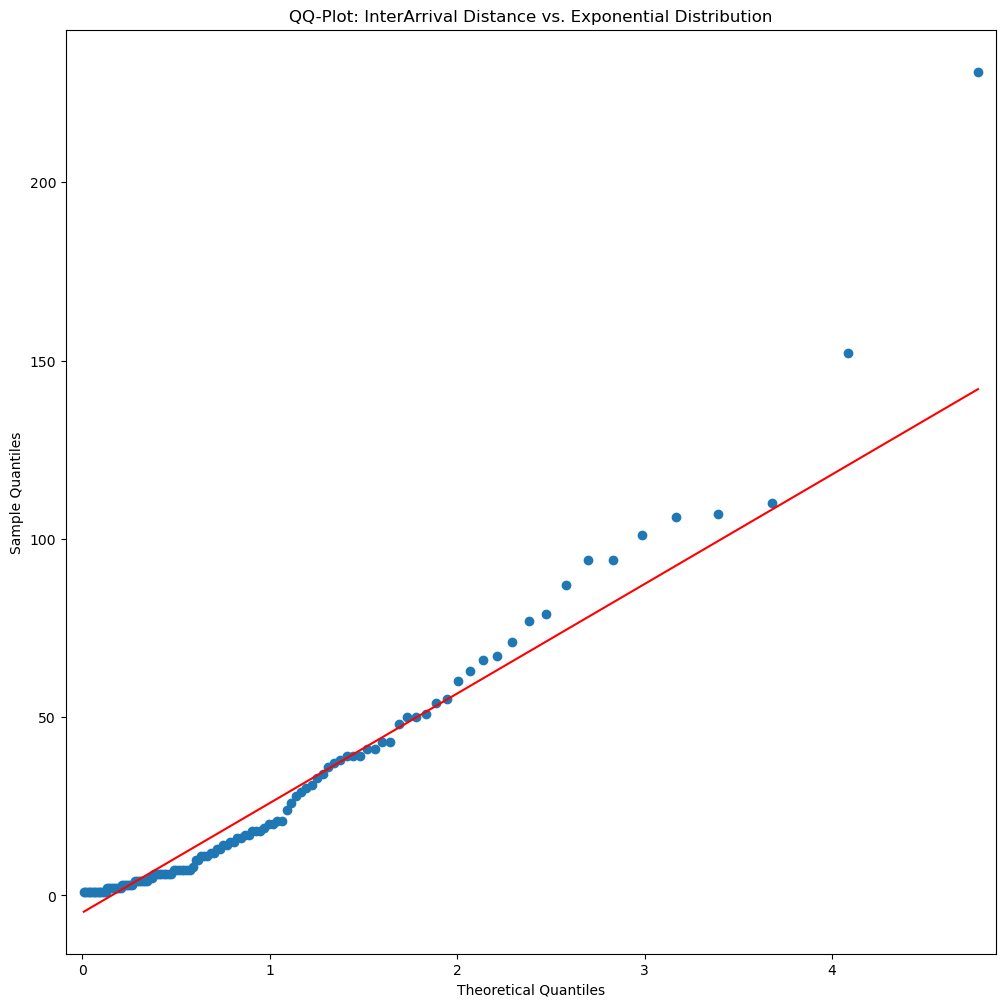


Average ES Real and Theoretical:  13186242.659420528 13932211.047711615
ES t-Test significance of difference:  0.50471664616147  | Reject if <0.05




In [179]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  3181206.82956074 2785923.4310867446
ES t-Test significance of difference:  0.2690862981788452  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  9

Average ES Real and Theoretical:  3322762.338437775 4012059.9979316387
ES t-Test significance of difference:  3.69650902301526e-12  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  3
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4138677.397039436 4083897.5851190393
ES t-Test significance of difference:  0.935746448160033  | Reject if <0.05



Variance Covariance t-Stu

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


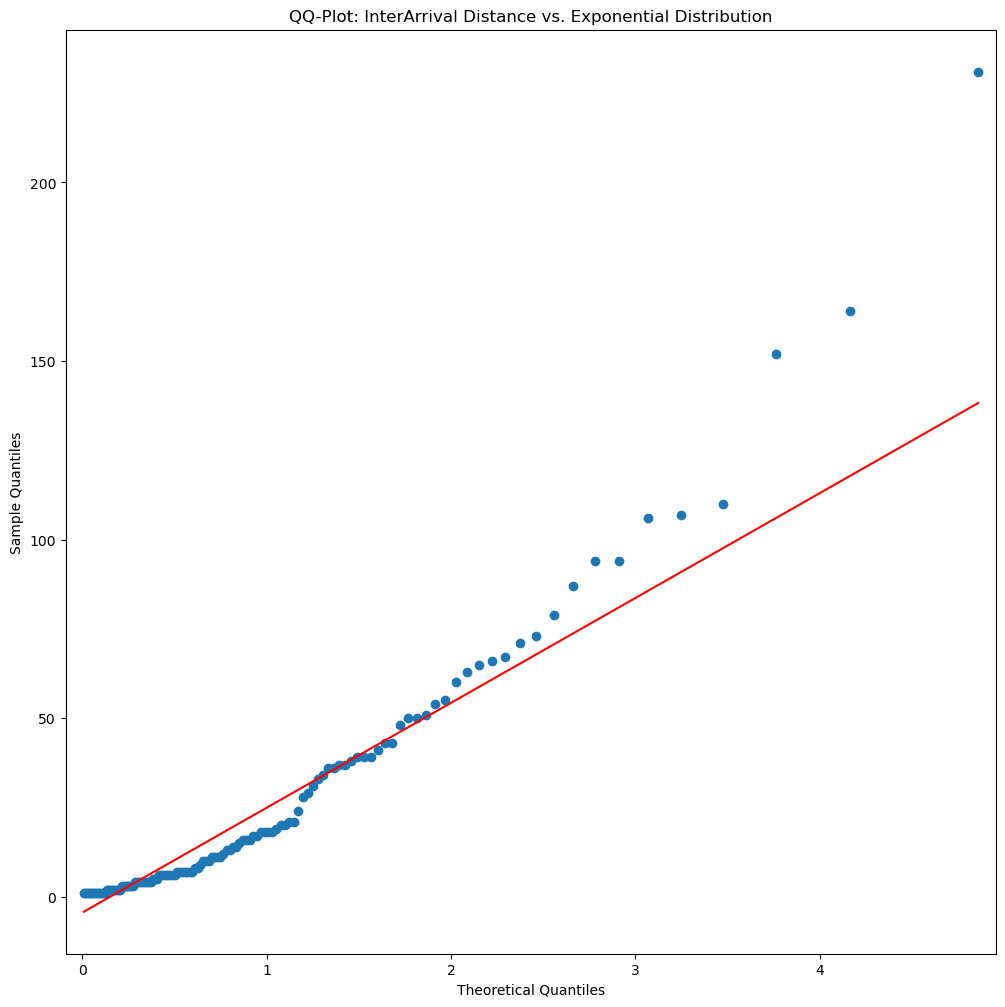


Average ES Real and Theoretical:  13185880.383540945 13038063.077708632
ES t-Test significance of difference:  0.8884244142889012  | Reject if <0.05




In [180]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  13

Average ES Real and Theoretical:  3070308.899029215 2592821.761365654
ES t-Test significance of difference:  0.16871182138498741  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  9

Average ES Real and Theoretical:  3322762.338437775 3763031.3195161936
ES t-Test significance of difference:  9.07811354953195e-06  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3783347.2727226503 3820287.997496265
ES t-Test significance of difference:  0.9505222764467304  | Reject if <0.05



Variance Covariance t-S

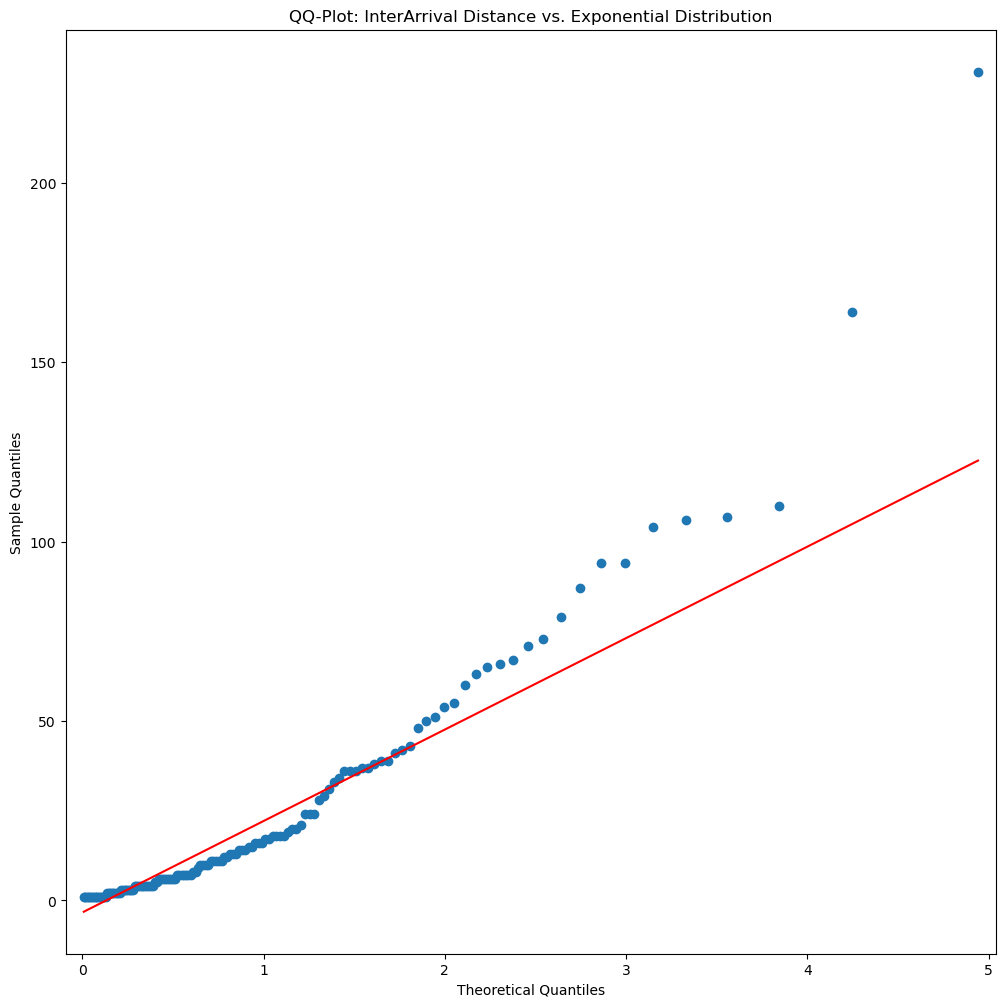


Average ES Real and Theoretical:  13175651.161771249 12678893.503591537
ES t-Test significance of difference:  0.6187276799552741  | Reject if <0.05




In [181]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  22
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2465705.441709209 2356505.879941259
ES t-Test significance of difference:  0.6749278099835976  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  18

Average ES Real and Theoretical:  2870665.5297929063 3128621.844771923
ES t-Test significance of difference:  0.03378575855102301  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3327107.6287444285 3148688.9158503343
ES t-Test significance of difference:  0.7083564515578167  | Reject if <

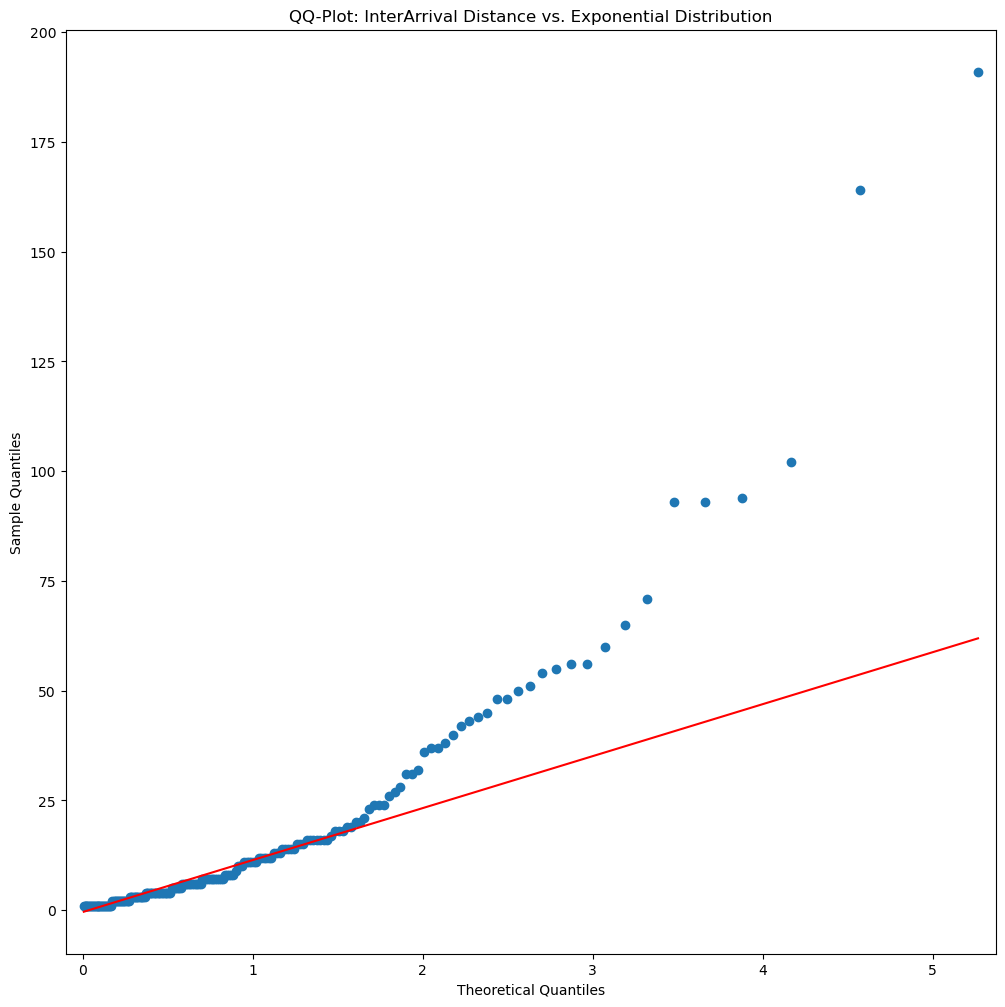


Average ES Real and Theoretical:  12161992.036661338 11704722.033714792
ES t-Test significance of difference:  0.568745610319567  | Reject if <0.05




In [182]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  13

Average ES Real and Theoretical:  3068805.923119406 2416618.58110118
ES t-Test significance of difference:  0.06032403236588133  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  14

Average ES Real and Theoretical:  3004919.806366618 2999057.7426161715
ES t-Test significance of difference:  0.9651903781982446  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3290997.2275574785 2792839.260125129
ES t-Test significance of difference:  0.30752308054799293  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2014 

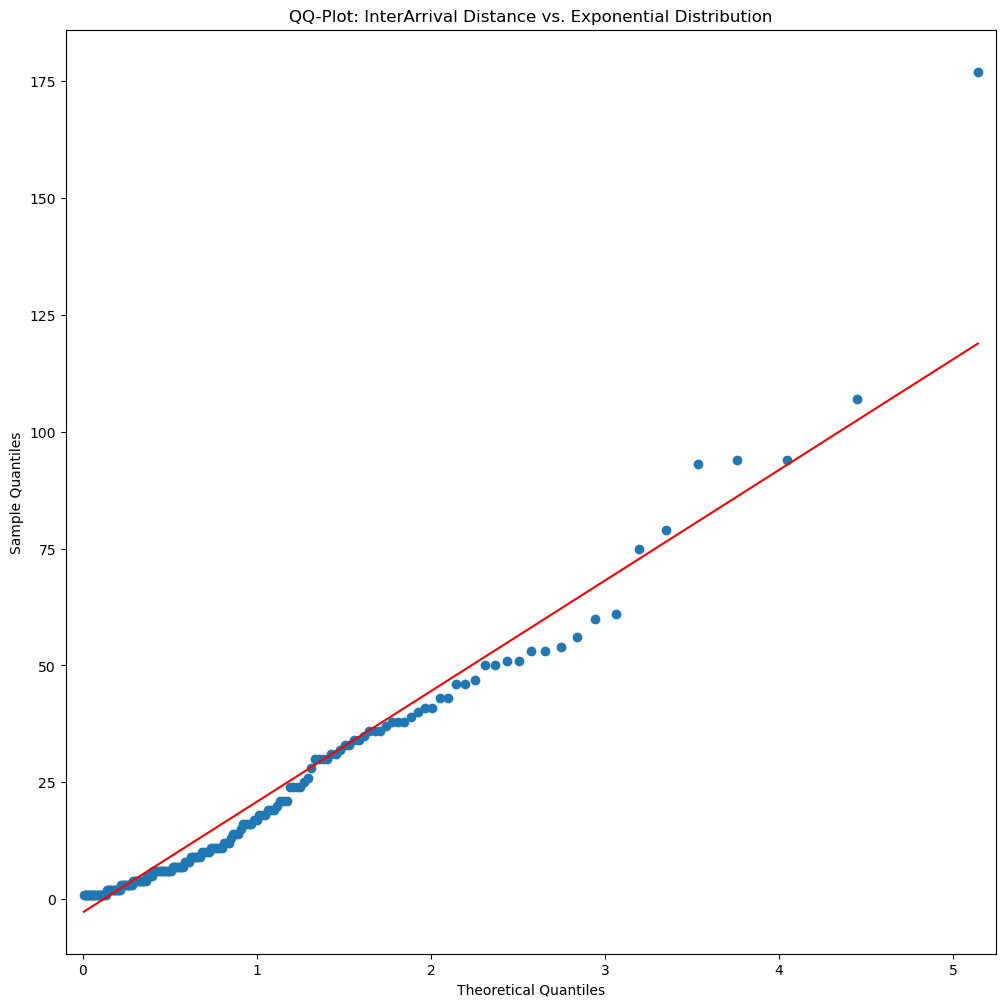


Average ES Real and Theoretical:  12635869.028523177 10835215.902886556
ES t-Test significance of difference:  0.040433666110391044  | Reject if <0.05




In [183]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  15

Average ES Real and Theoretical:  2794957.453622405 2571695.365443869
ES t-Test significance of difference:  0.5172385693852478  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  12

Average ES Real and Theoretical:  3092653.2247034223 3464710.092593405
ES t-Test significance of difference:  0.008367701462957922  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  7

Average ES Real and Theoretical:  3102525.7196940403 2608397.3640164244
ES t-Test significance of difference:  0.27575299936393016  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2014 | Trading Days=258
Expected number of VaR violations: 1

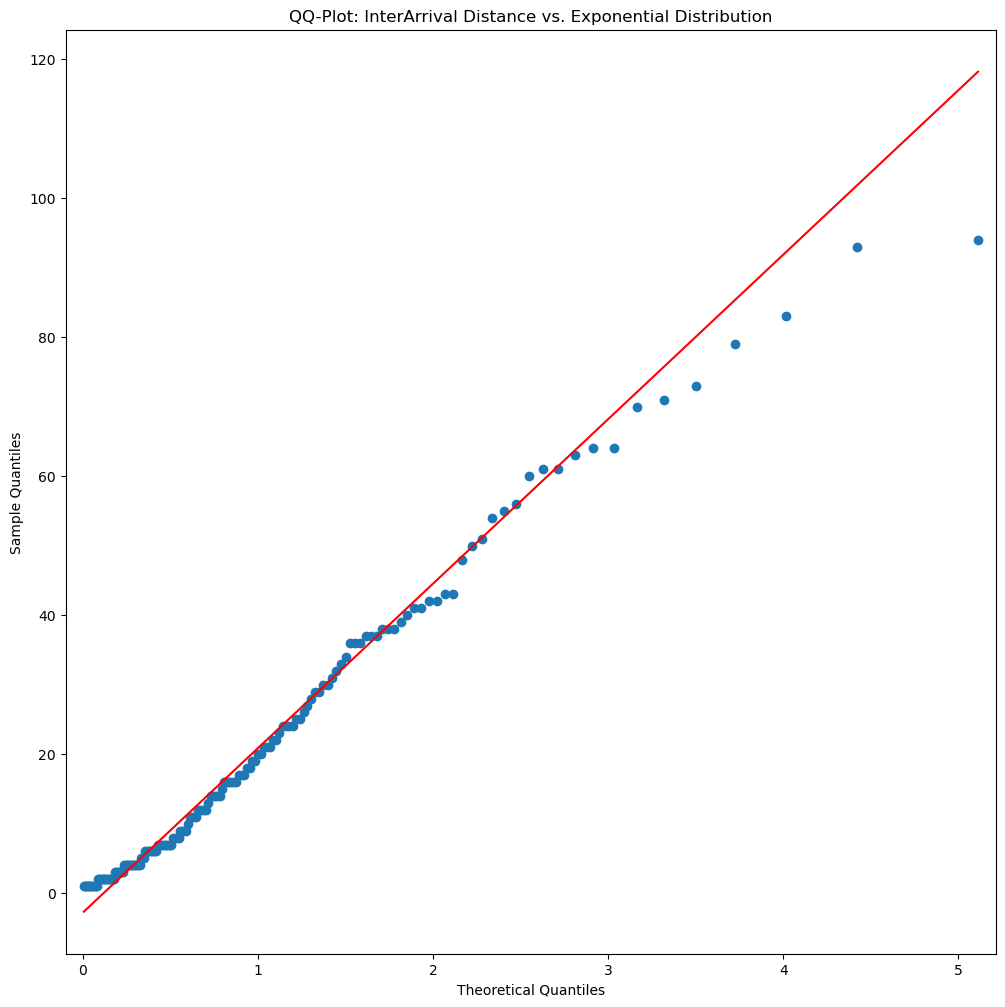


Average ES Real and Theoretical:  11595758.495927824 11811496.291814305
ES t-Test significance of difference:  0.804789677704146  | Reject if <0.05




In [184]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

## VaR_99

In [185]:
alpha = .99

### Var-CoVaR


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3497132.9189220075 2519147.032984751
ES t-Test significance of difference:  0.020721270941430597  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  6

Average ES Real and Theoretical:  3500211.602844333 3757470.0372467493
ES t-Test significance of difference:  2.96293483774177e-05  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  4138677.397039436 3766081.7611279716
ES t-Test significance of difference:  0.5834631507840273  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=201

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


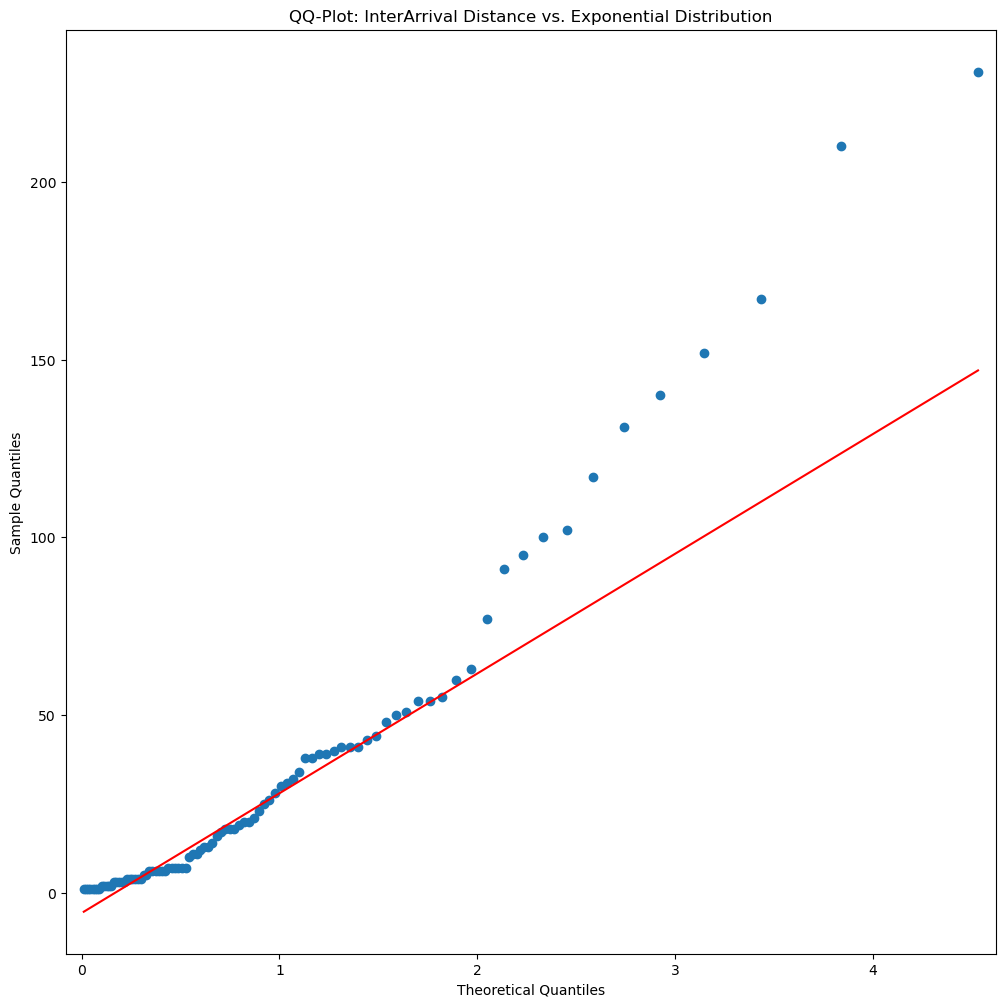


Average ES Real and Theoretical:  14761794.73403544 12308423.525817804
ES t-Test significance of difference:  0.06516052224947605  | Reject if <0.05




In [186]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  5044184.668927313 4705886.110909656
ES t-Test significance of difference:  0.45304996882812887  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799549.1784944665 7802448.266512419
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Viola

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


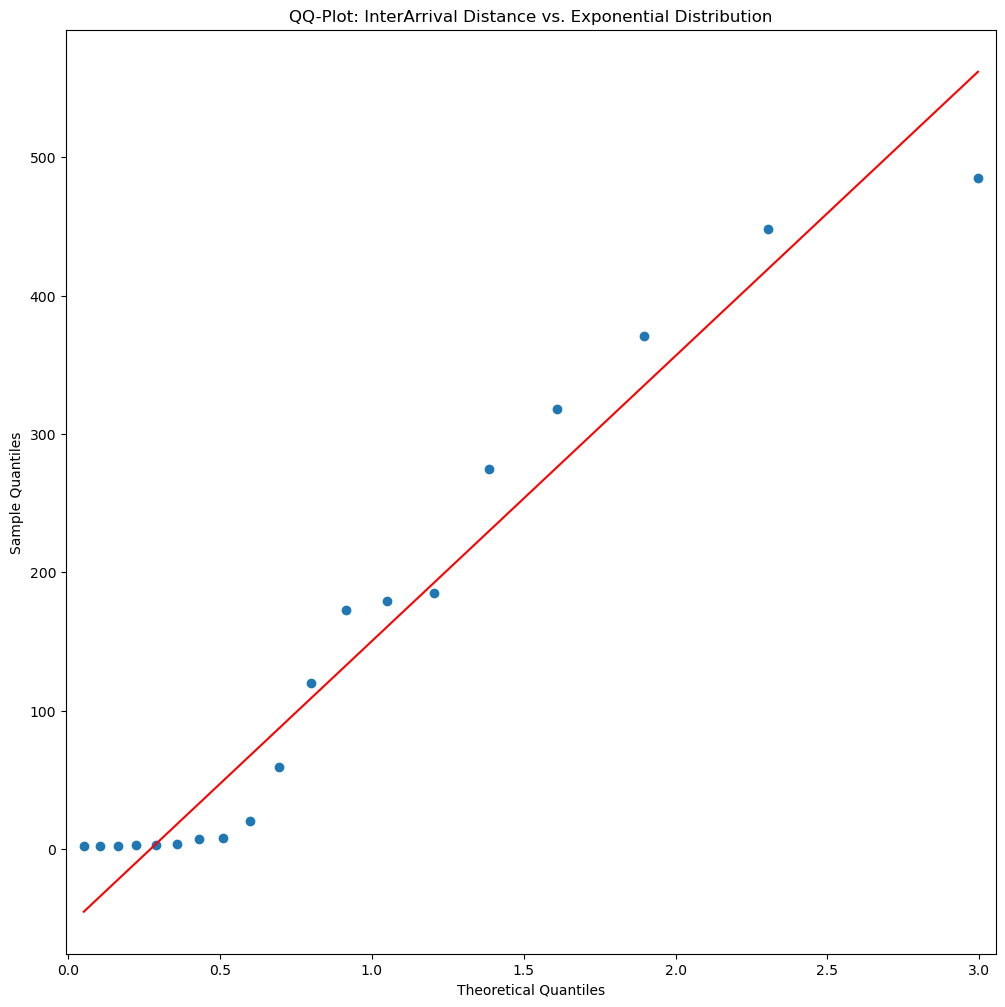


Average ES Real and Theoretical:  20240936.2953751 21731093.0682174
ES t-Test significance of difference:  0.6370102112049545  | Reject if <0.05




In [187]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  4703623.3860325245 4210333.065636946
ES t-Test significance of difference:  0.27160025508109564  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799549.1784944665 6654398.53301569
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Viola

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


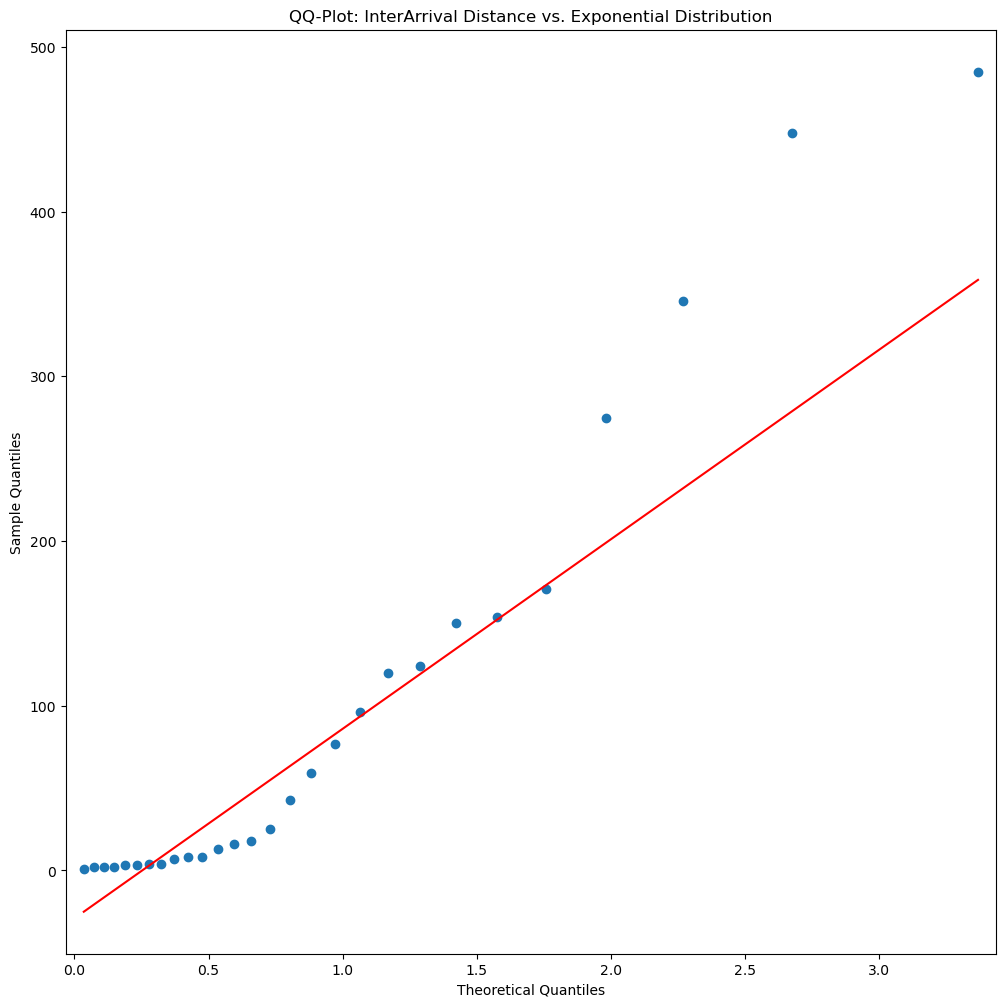


Average ES Real and Theoretical:  18076618.061460063 17870705.427473743
ES t-Test significance of difference:  0.9330328299673969  | Reject if <0.05




In [188]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  4703623.3860325245 3813263.322277956
ES t-Test significance of difference:  0.047219618376842507  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799549.1784944665 6026832.904234905
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Vio

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


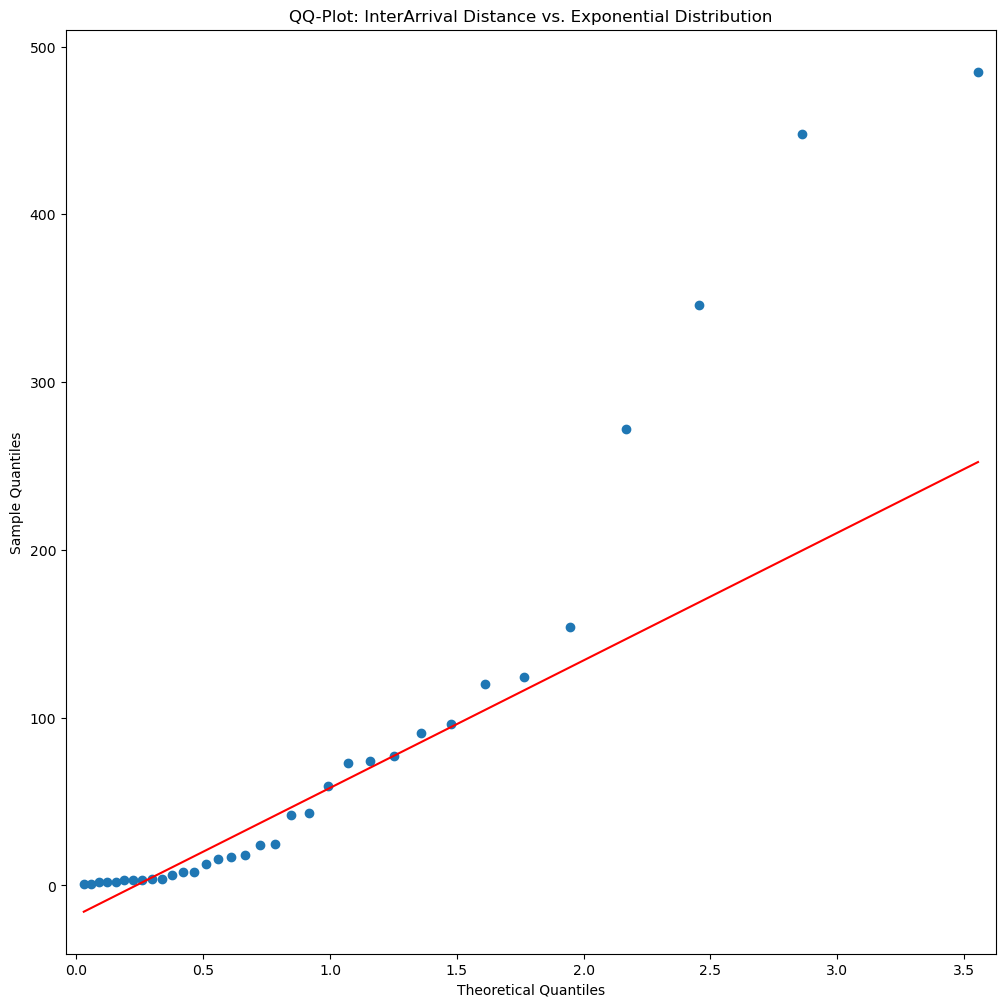


Average ES Real and Theoretical:  17448267.69025268 16531964.977503838
ES t-Test significance of difference:  0.6674336533425784  | Reject if <0.05




In [189]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5

Average ES Real and Theoretical:  4055351.867744915 3821349.50956164
ES t-Test significance of difference:  0.7006811949292588  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  2

Average ES Real and Theoretical:  3504689.5643965425 3640957.021931013
ES t-Test significance of difference:  2.9227915751226246e-05  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799549.1784944665 3681286.048815574
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023


C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


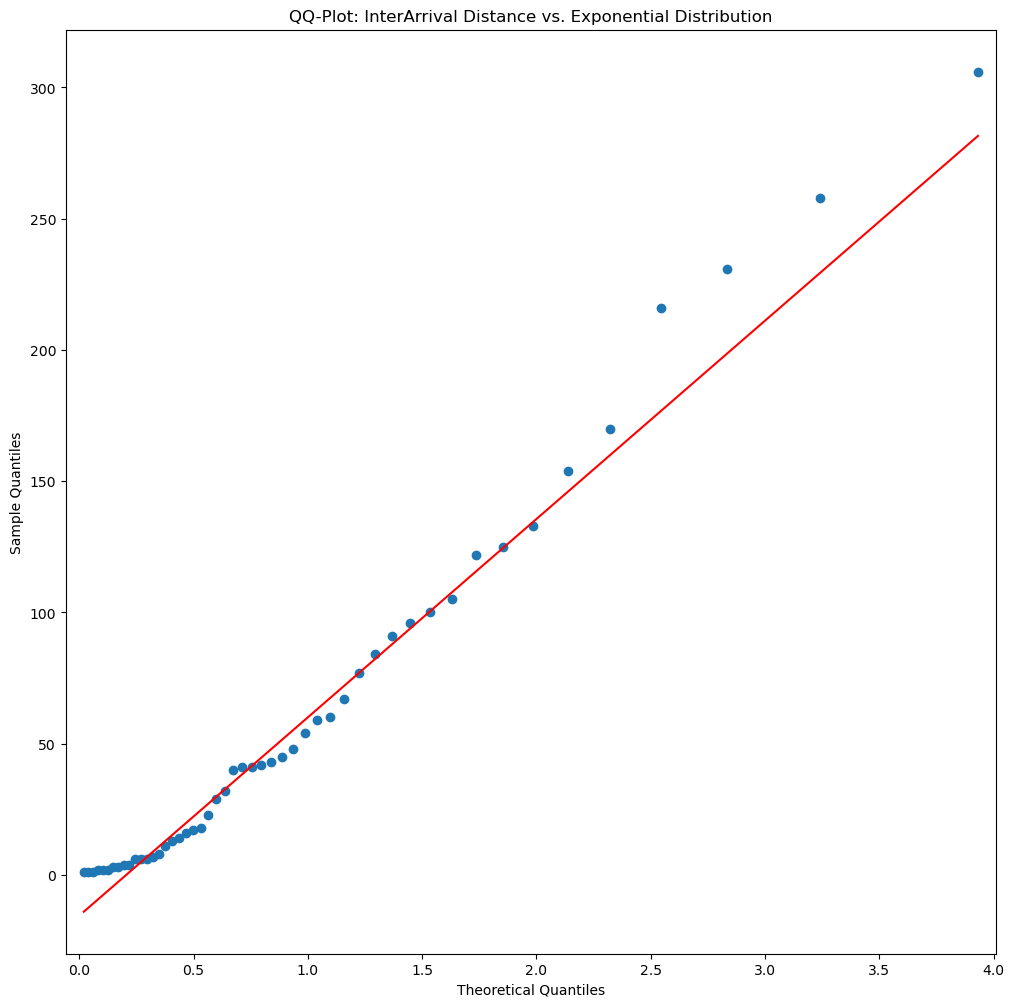


Average ES Real and Theoretical:  16641070.831998318 16015108.506357392
ES t-Test significance of difference:  0.7511263046380569  | Reject if <0.05




In [190]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  7
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3791172.3052148037 3151701.222032644
ES t-Test significance of difference:  0.1876130273497717  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  3

Average ES Real and Theoretical:  3327278.7421066836 3457432.597250192
ES t-Test significance of difference:  0.5172181249200425  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  4138677.397039436 3721831.9140231274
ES t-Test significance of difference:  0.5395763233488825  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | 

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


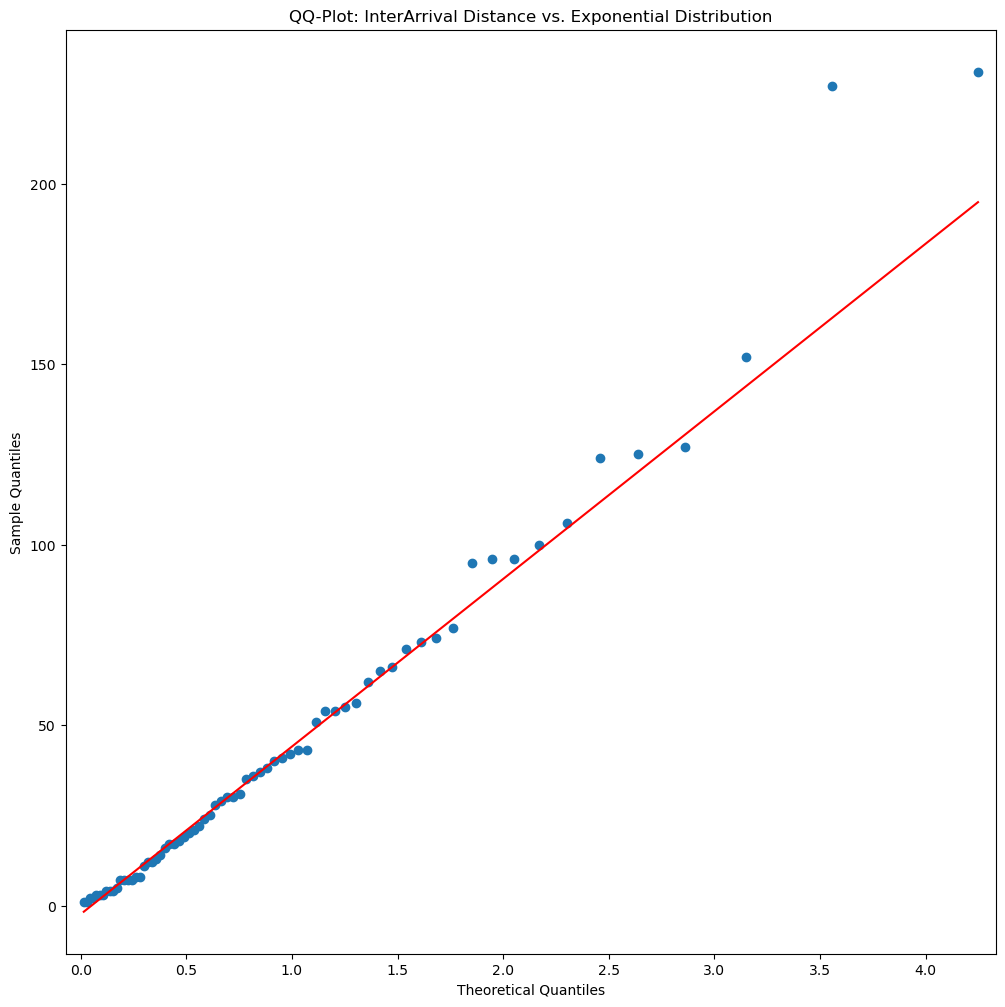


Average ES Real and Theoretical:  15552746.969793981 13134413.379822025
ES t-Test significance of difference:  0.11182672666186692  | Reject if <0.05




In [191]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  5044184.668927313 4392645.854260451
ES t-Test significance of difference:  0.14842948714090853  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  2

Average ES Real and Theoretical:  3309532.064219773 3584297.2933116234
ES t-Test significance of difference:  0.009132262636529978  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  3783347.2727226503 3559175.1317003183
ES t-Test significance of difference:  0.7065068604970268  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


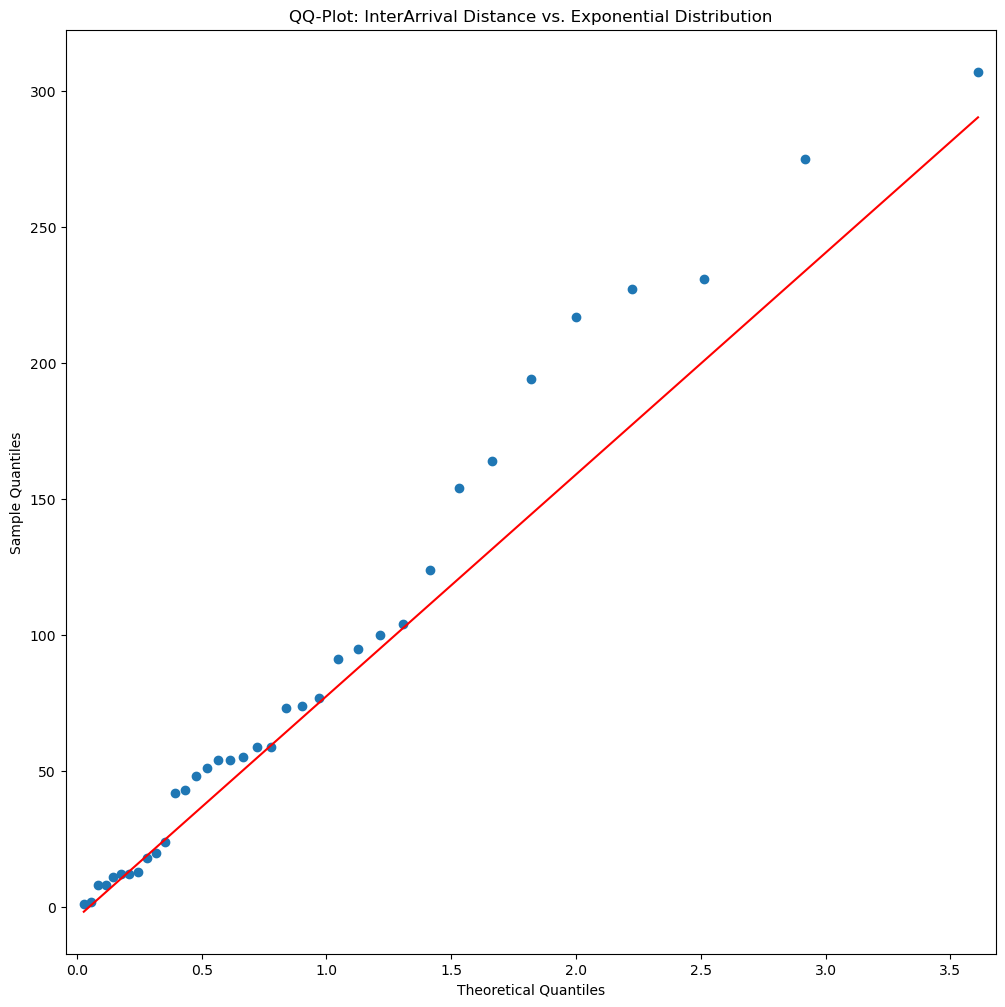


Average ES Real and Theoretical:  15362252.726434946 15121324.588532805
ES t-Test significance of difference:  0.90911359128063  | Reject if <0.05




In [192]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

# Stress Testing

## Shocking APPL by -20-40%

It is exactly same portfolio otherwise, thus we can compare with the previously obtained VaR/ES

## Shocking Interest Rates by +1-2% 
It is exactly same portfolio otherwise, thus we can compare with the previously obtained VaR/ES

In [340]:
# Getting raw data to introduce a shock

# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()

[**********************83%%**************        ]  5 of 6 completed

[*********************100%%**********************]  6 of 6 completed


In [ ]:
# Shocking AAPL

# Shocking AAPL on the last week of 2021
start_date = '2021-12-23'
end_date = '2022-01-01'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

# Shocking AAPL on the last week of 2021
start_date = '2021-12-25'
end_date = '2021-12-27'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

In [341]:
# Shocking Interest Rates

# Shocking AAPL on the last week of 2021
start_date = '2021-12-23'
end_date = '2022-01-01'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "EURIBOR"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "EURIBOR"] + 1.0        # Keeping only the related dates

# Shocking AAPL on the last week of 2021
start_date = '2021-12-25'
end_date = '2021-12-27'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "EURIBOR"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "EURIBOR"] + 1.0        # Keeping only the related dates

In [342]:
# Obtaining Loss Operator

credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])
portfolio_loss, ind_loss = loss_operator(data, weights)

In [343]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = indexes_year_changes[0]                           # Days in the first period which are used to train VaR
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped

Indexes where year changes:  [259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


In [344]:
indexes_year_changes

array([   1,  259,  518,  776, 1034, 1292, 1550, 1808, 2066, 2325, 2584,
       2843, 3101, 3358])

### .95

In [345]:
alpha = .95

In [346]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  23
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  29975121.455582846 27866183.547551684
ES t-Test significance of difference:  0.14746232093567088  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  25301459.88655539 27066888.163605995
ES t-Test significance of difference:  0.01723150980219138  | Reject if <0.05




In [347]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  11

Average ES Real and Theoretical:  36069702.26523316 44184793.20210102
ES t-Test significance of difference:  5.709264645956492e-10  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [348]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  35057051.56337399 39324110.31187075
ES t-Test significance of difference:  0.005679884464220543  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  27452377.155525934 37919333.03469286
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


In [349]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  14

Average ES Real and Theoretical:  33639459.98319886 36608649.10670096
ES t-Test significance of difference:  0.07233732708009014  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  26611522.836694166 35597391.554706536
ES t-Test significance of difference:  1.3269222886472299e-51  | Reject if <0.05




In [350]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  24
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  29526914.04999702 30099133.923772853
ES t-Test significance of difference:  0.6956229423435527  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  24211419.16636639 27482686.989028025
ES t-Test significance of difference:  0.004148023153567417  | Reject if <0.05




In [351]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  19

Average ES Real and Theoretical:  31883821.380526066 29934085.039246295
ES t-Test significance of difference:  0.16491100371728906  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  7

Average ES Real and Theoretical:  23214221.719568793 25049759.655101303
ES t-Test significance of difference:  0.07306125793919911  | Reject if <0.05




In [352]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  35494765.98685479 36322711.70769878
ES t-Test significance of difference:  0.5306212154879137  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  10

Average ES Real and Theoretical:  21198367.6781866 23435493.381429642
ES t-Test significance of difference:  0.07143027424316224  | Reject if <0.05




### .99

In [353]:
alpha = .99

In [354]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  36578036.26297818 36845660.70290042
ES t-Test significance of difference:  0.8414501021531986  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [355]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [356]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [357]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [358]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  6

Average ES Real and Theoretical:  38405678.699670695 40845539.61051884
ES t-Test significance of difference:  0.15036687835742388  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [359]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  6

Average ES Real and Theoretical:  36873407.10990702 34768392.47456228
ES t-Test significance of difference:  0.33805423289244985  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [360]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  38301182.3394767 42653640.09553684
ES t-Test significance of difference:  0.13897728721119784  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  1

Average ES Real and Theoretical:  27452377.155525934 33022957.711286638
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


In [361]:
# Getting raw data to introduce a shock

# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()

[*********************100%%**********************]  6 of 6 completed


In [362]:
# Shocking Parameters

# Shocking AAPL on the last week of 2021
start_date = '2021-12-23'
end_date = '2022-01-01'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

# Shocking AAPL on the last week of 2021
start_date = '2021-12-25'
end_date = '2021-12-27'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

In [363]:
# Obtaining Loss Operator

credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])
portfolio_loss, ind_loss = loss_operator(data, weights)

In [364]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = indexes_year_changes[0]                           # Days in the first period which are used to train VaR
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped

Indexes where year changes:  [259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


In [365]:
indexes_year_changes

array([   1,  259,  518,  776, 1034, 1292, 1550, 1808, 2066, 2325, 2584,
       2843, 3101, 3358])

### .95

In [366]:
alpha = .95

In [367]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  11

Average ES Real and Theoretical:  36069702.26523316 37680556.94304151
ES t-Test significance of difference:  0.2185621165245074  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  25301459.88655539 27066888.163605995
ES t-Test significance of difference:  0.01723150980219138  | Reject if <0.05




In [368]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  40224893.35642983 58774608.04105486
ES t-Test significance of difference:  1.2610823050589349e-11  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [369]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  39750012.27995285 54063368.4651189
ES t-Test significance of difference:  2.3422459554656995e-24  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  27452377.155525934 37919333.03469286
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


In [370]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  39750012.27995285 50707653.64368136
ES t-Test significance of difference:  6.377546564912759e-15  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  26611522.836694166 35597391.554706536
ES t-Test significance of difference:  1.3269222886472299e-51  | Reject if <0.05




In [371]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  20

Average ES Real and Theoretical:  31059422.87293316 42648265.21993083
ES t-Test significance of difference:  1.1626250474470849e-14  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  24211419.16636639 27482686.989028025
ES t-Test significance of difference:  0.004148023153567417  | Reject if <0.05




In [372]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  18

Average ES Real and Theoretical:  32016874.34172098 30672310.024000764
ES t-Test significance of difference:  0.35352076338215943  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  24554378.76275466 27838611.938783646
ES t-Test significance of difference:  0.00023677388657066068  | Reject if <0.05




In [373]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  9

Average ES Real and Theoretical:  35649896.088833995 42919642.38534665
ES t-Test significance of difference:  0.00014498172693954328  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  10

Average ES Real and Theoretical:  21198367.6781866 23349832.5738574
ES t-Test significance of difference:  0.08297050700629857  | Reject if <0.05




### .99

In [374]:
alpha = .99

In [375]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [376]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [377]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [378]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [379]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [380]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5

Average ES Real and Theoretical:  37715552.044301495 35177903.10170721
ES t-Test significance of difference:  0.29253454503156184  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [381]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  2

Average ES Real and Theoretical:  43443728.428081654 69430272.31169394
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  1

Average ES Real and Theoretical:  27452377.155525934 33012710.163223784
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19296\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
